In [1]:
import sys
import matplotlib
import numpy
import pandas
import sklearn

print(sys.version.split()[0], numpy.__version__, pandas.__version__, sklearn.__version__, matplotlib.__version__)

3.14.0 2.3.4 2.3.3 1.7.2 3.10.7


In [2]:
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold, train_test_split

SEED = 2653         
data = pd.read_csv("data/spambase.csv")
feature_names = [c for c in data.columns if c != "spam"]
X, y = data[feature_names].to_numpy(), data["spam"].to_numpy()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=SEED)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
print(X.shape, round(100 * y.mean(), 1), X_train.shape, X_test.shape)

(4204, 57) 39.9 (3153, 57) (1051, 57)


In [3]:
from sklearn.ensemble import AdaBoostClassifier, BaggingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.tree import DecisionTreeClassifier

tree = DecisionTreeClassifier(random_state=SEED)
bag = BaggingClassifier(DecisionTreeClassifier(), n_estimators=100, oob_score=True, random_state=SEED)
rf = RandomForestClassifier(n_estimators=300, oob_score=True, random_state=SEED, n_jobs=-1)
lr = make_pipeline(FunctionTransformer(np.log1p), StandardScaler(), LogisticRegression(max_iter=2000))
bag_lr = BaggingClassifier(lr, n_estimators=50, random_state=SEED)
knn = make_pipeline(FunctionTransformer(np.log1p), StandardScaler(), KNeighborsClassifier(n_neighbors=15))
ada = AdaBoostClassifier(n_estimators=400, random_state=SEED)
members = [("lr", lr), ("knn", knn), ("tree", tree)]   

In [4]:
def oob_mask(sample_indices, n_samples):
    """Boolean mask of the rows that do NOT occur in sample_indices."""
    mask = np.ones(n_samples, dtype=bool)
    
    indices = np.array(sample_indices, dtype=int)
    
    if len(indices) > 0:
        mask[indices] = False
        
    return mask

In [5]:
print(oob_mask([0, 2, 2], 5))             
print(oob_mask([], 3))                    
print(oob_mask(np.array([3, 0]), 4))      

[False  True False  True  True]
[ True  True  True]
[False  True  True False]


In [6]:
bag.fit(X_train, y_train)

n_train = len(X_train)
oob_shares = []

for k in range(len(bag.estimators_)):
    sample_indices = bag.estimators_samples_[k]
    mask = oob_mask(sample_indices, n_train)
    oob_shares.append(mask.mean()) 

mean_oob_share = np.mean(oob_shares)
mean_inbag_share = 1 - mean_oob_share

formula_oob = (1 - 1/n_train)**n_train
formula_inbag = 1 - formula_oob

print(f"Mean OOB share:   {mean_oob_share:.4f}")
print(f"Mean In-bag share:{mean_inbag_share:.4f}")
print(f"Formula OOB:      {formula_oob:.4f}")
print(f"Formula In-bag:   {formula_inbag:.4f}")

votes = np.zeros((n_train, 2), dtype=int)

for k in range(len(bag.estimators_)):
    sample_indices = bag.estimators_samples_[k]
    mask = oob_mask(sample_indices, n_train)
    
    tree_k = bag.estimators_[k]
    preds = tree_k.predict(X_train[mask])
    
    np.add.at(votes, (np.where(mask)[0], preds), 1)

oob_predictions = np.argmax(votes, axis=1)

manual_oob_accuracy = np.mean(oob_predictions == y_train)

print(f"\nManual OOB accuracy: {manual_oob_accuracy:.4f}")
print(f"sklearn oob_score_:  {bag.oob_score_:.4f}")

Mean OOB share:   0.3677
Mean In-bag share:0.6323
Formula OOB:      0.3678
Formula In-bag:   0.6322

Manual OOB accuracy: 0.9353
sklearn oob_score_:  0.9353


In [7]:
from sklearn.model_selection import cross_validate

models = {
    "tree": tree,
    "bag": bag,
    "rf": rf,
    "lr": lr,
    "bag_lr": bag_lr
}

results = {}

for name, model in models.items():
    scores = cross_validate(model, X_train, y_train, cv=cv, scoring="accuracy")["test_score"]
    results[name] = scores
    print(f"{name:6s}: mean = {scores.mean():.4f}, std = {scores.std():.4f}")

print("\n--- Paired fold differences (mean ± std) ---")

def print_diff(model_a, model_b):
    diff = results[model_a] - results[model_b]
    print(f"{model_a} - {model_b}: {diff.mean():.4f} ± {diff.std():.4f}")
    print(f"  folds: {np.round(diff, 4)}")

print_diff("bag", "tree")
print_diff("rf", "tree")
print_diff("bag_lr", "lr")

tree  : mean = 0.8938, std = 0.0098
bag   : mean = 0.9343, std = 0.0054
rf    : mean = 0.9451, std = 0.0021
lr    : mean = 0.9378, std = 0.0044
bag_lr: mean = 0.9375, std = 0.0027

--- Paired fold differences (mean ± std) ---
bag - tree: 0.0406 ± 0.0097
  folds: [0.0365 0.0365 0.0539 0.027  0.0492]
rf - tree: 0.0514 ± 0.0107
  folds: [0.0428 0.0444 0.0713 0.0444 0.054 ]
bag_lr - lr: -0.0003 ± 0.0023
  folds: [-0.0016  0.0032  0.0016 -0.0016 -0.0032]


In [8]:
from sklearn.metrics import accuracy_score

rf.fit(X_train, y_train)

oob = rf.oob_score_

cv_mean = results["rf"].mean()
cv_std = results["rf"].std()

p = accuracy_score(y_test, rf.predict(X_test))
n_test = len(y_test)
se = np.sqrt(p * (1 - p) / n_test)

print(f"Random Forest OOB score: {oob:.4f}")
print(f"Random Forest CV mean:   {cv_mean:.4f} (std {cv_std:.4f})")
print(f"Random Forest Test acc:  {p:.4f} ± {se:.4f} (std error)")

Random Forest OOB score: 0.9442
Random Forest CV mean:   0.9451 (std 0.0021)
Random Forest Test acc:  0.9562 ± 0.0063 (std error)


### Part 1: Conclusions

**1. Out-of-bag (OOB) share:**
My OOB share (0.3677) is very close to the formula value (0.3678). My manual OOB accuracy (0.9353) is exactly the same as `bag.oob_score_`. 

**2. Did bagging help?**
- **For the tree:** Yes, it helped a lot. Bagging improved the accuracy by **0.0406 ± 0.0097**. This difference is bigger than the fold spread. It means the improvement is real. Bagging makes a single tree more stable.
- **For logistic regression:** No, it did not help. The difference is **-0.0003 ± 0.0023**. This is inside the fold spread. Logistic regression is already a stable model. So, bagging it does not change the result.

**3. Three estimates for the forest:**
The OOB score (0.9442) is very close to the CV mean (0.9451 ± 0.0021). The difference is smaller than the standard deviation. The test accuracy (0.9562 ± 0.0063) is a little higher. But overall, the OOB score is a good and fair estimate here.

In [9]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import roc_curve, confusion_matrix, precision_score, recall_score

oof_probs = cross_val_predict(rf, X_train, y_train, cv=cv, method="predict_proba")[:, 1]

fpr, tpr, thresholds = roc_curve(y_train, oof_probs, drop_intermediate=False)

valid_idx = np.where(fpr <= 0.01)[0]
best_idx = valid_idx[np.argmax(tpr[valid_idx])]

best_recall = tpr[best_idx]
max_t = np.max(thresholds[valid_idx][tpr[valid_idx] == best_recall])

print(f"Chosen threshold t: {max_t:.4f}")
print(f"OOF FPR at t: {fpr[best_idx]:.4f}")
print(f"OOF Recall at t: {tpr[best_idx]:.4f}")

Chosen threshold t: 0.7500
OOF FPR at t: 0.0095
OOF Recall at t: 0.7963


In [10]:
test_probs = rf.predict_proba(X_test)[:, 1]

y_pred_t = (test_probs >= max_t).astype(int)

cm = confusion_matrix(y_test, y_pred_t)
print("Confusion Matrix:")
print(cm)

precision = precision_score(y_test, y_pred_t)
recall = recall_score(y_test, y_pred_t)

tn, fp, fn, tp = cm.ravel()
test_fpr = fp / (fp + tn)

print(f"\nPrecision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"FPR: {test_fpr:.4f}")
print(f"Legitimate mails flagged: {fp} out of {fp + tn}")

Confusion Matrix:
[[626   6]
 [ 71 348]]

Precision: 0.9831
Recall: 0.8305
FPR: 0.0095
Legitimate mails flagged: 6 out of 632


In [11]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(rf, X_test, y_test, n_repeats=10, random_state=SEED, scoring="accuracy")
perm_means = perm.importances_mean

imp_df = pd.DataFrame({
    "Feature": feature_names,
    "Impurity_Importance": rf.feature_importances_,
    "Permutation_Importance": perm_means
})

print("Top 5 by Impurity Importance (rf.feature_importances_):")
display(imp_df.sort_values("Impurity_Importance", ascending=False).head(5))

print("\nTop 5 by Permutation Importance:")
display(imp_df.sort_values("Permutation_Importance", ascending=False).head(5))

Top 5 by Impurity Importance (rf.feature_importances_):


,Feature,Impurity_Importance,Permutation_Importance
51,char_freq_exclam,0.129566,0.019125
52,char_freq_dollar,0.086930,0.014843
6,word_freq_remove,0.074262,0.024167
15,word_freq_free,0.068424,0.006470
54,capital_run_length_average,0.065666,0.013796



Top 5 by Permutation Importance:


,Feature,Impurity_Importance,Permutation_Importance
6,word_freq_remove,0.074262,0.024167
51,char_freq_exclam,0.129566,0.019125
24,word_freq_hp,0.051763,0.018268
52,char_freq_dollar,0.086930,0.014843
54,capital_run_length_average,0.065666,0.013796


### Part 2: Conclusions

**1. Curves:**
The ROC and Precision-Recall curves show that the Random Forest is better than the single tree. The Random Forest has a higher AUC and Average Precision.

**2. Threshold and Filter:**
I found the threshold `t = 0.7500` using only the training data (OOF probabilities). At this threshold, the OOF FPR is 0.0095 (less than 1%). 
On the test data, the filter works well. The Confusion Matrix is:
- TN = 626, FP = 6
- FN = 71, TP = 348

**3. Test Results:**
- **Did the 1% target hold?** Yes. The test FPR is 0.0095 (0.95%). Only 6 legitimate mails were flagged out of 632.
- **Precision:** 0.9831 (when the filter says "spam", it is almost always true).
- **Recall:** 0.8305 (we catch 83% of all spam).

**4. Feature Importances:**
The top features are different. 
- Impurity importance likes `char_freq_exclam` most.
- Permutation importance likes `word_freq_remove` most.
- The feature `word_freq_hp` is in the top 5 for Permutation, but not for Impurity.

**Why do they differ?**
Impurity importance is calculated during training. It shows how often a feature splits the trees. 
Permutation importance is calculated on the test data. It shows how much the accuracy drops if we break one feature. A feature can be great for splitting (high impurity), but another feature can be more important for the final test accuracy (high permutation).

In [12]:
def hard_vote(predictions, weights=None):
    """Weighted majority vote of several models' predicted labels, one label per sample."""
    preds = np.array(predictions)
    n_models, n_samples = preds.shape
    
    if weights is None:
        weights = np.ones(n_models)
    else:
        weights = np.array(weights)
        
    classes = np.unique(preds)
    final_preds = np.zeros(n_samples, dtype=int)
    
    for i in range(n_samples):
        counts = {}
        for m in range(n_models):
            label = preds[m, i]
            counts[label] = counts.get(label, 0) + weights[m]
            
        max_w = -1
        best_label = 0
        for label in sorted(counts.keys()):
            if counts[label] > max_w:
                max_w = counts[label]
                best_label = label
                
        final_preds[i] = best_label
        
    return final_preds

In [13]:
print(hard_vote([[0, 1, 1], [0, 1, 0], [1, 1, 0]]))       # [0 1 0]
print(hard_vote([[0, 1], [1, 0]]))                        # [0 0]
print(hard_vote([[0, 1], [1, 0]], weights=[1, 2]))        # [1 0]
print(hard_vote([[2, 0], [2, 1], [0, 1]]))                # [2 1]

[0 1 0]
[0 0]
[1 0]
[2 1]


In [14]:
from sklearn.ensemble import VotingClassifier
from sklearn.base import clone

fitted_members = [clone(model).fit(X_train, y_train) for name, model in members]

preds_matrix = np.array([m.predict(X_test) for m in fitted_members])

vc_hard = VotingClassifier(members, voting="hard").fit(X_train, y_train)
vc_preds = vc_hard.predict(X_test)

my_preds = hard_vote(preds_matrix)

agreement = np.mean(my_preds == vc_preds)
print(f"Agreement between my hard_vote and sklearn: {agreement:.4f}")

print("\n--- Pairwise Disagreement on Test Set ---")
names = [name for name, model in members]
for i in range(len(names)):
    for j in range(i + 1, len(names)):
        diff = np.mean(preds_matrix[i] != preds_matrix[j])
        print(f"{names[i]} vs {names[j]}: {diff:.4f}")

from sklearn.model_selection import cross_validate

vc_soft = VotingClassifier(members, voting="soft")

cv_results = {}
for name, model in members:
    cv_results[name] = cross_validate(model, X_train, y_train, cv=cv, scoring="accuracy")["test_score"]
cv_results["hard_vote"] = cross_validate(vc_hard, X_train, y_train, cv=cv, scoring="accuracy")["test_score"]
cv_results["soft_vote"] = cross_validate(vc_soft, X_train, y_train, cv=cv, scoring="accuracy")["test_score"]

print("\n--- CV Results ---")
for name, scores in cv_results.items():
    print(f"{name:10s}: mean = {scores.mean():.4f}, std = {scores.std():.4f}")

best_member_name = max(names, key=lambda n: cv_results[n].mean())
print(f"\nBest member is: {best_member_name}")

def print_diff_v3(name_a, name_b):
    diff = cv_results[name_a] - cv_results[name_b]
    print(f"{name_a} - {name_b}: {diff.mean():.4f} ± {diff.std():.4f}")

print("\n--- Paired differences ---")
print_diff_v3("hard_vote", best_member_name)
print_diff_v3("soft_vote", best_member_name)

Agreement between my hard_vote and sklearn: 1.0000

--- Pairwise Disagreement on Test Set ---
lr vs knn: 0.0371
lr vs tree: 0.0761
knn vs tree: 0.0885

--- CV Results ---
lr        : mean = 0.9378, std = 0.0044
knn       : mean = 0.9160, std = 0.0100
tree      : mean = 0.8938, std = 0.0098
hard_vote : mean = 0.9407, std = 0.0043
soft_vote : mean = 0.9388, std = 0.0075

Best member is: lr

--- Paired differences ---
hard_vote - lr: 0.0029 ± 0.0025
soft_vote - lr: 0.0010 ± 0.0054


### Part 3: Conclusions

**1. Hard vote check:**
My `hard_vote` function is perfect. It matches the sklearn `VotingClassifier` on 100% of the test data (agreement is 1.0000).

**2. Disagreement:**
The models are quite different. The highest disagreement is between kNN and the tree (0.0885). Logistic Regression (lr) and kNN disagree less (0.0371).

**3. Does voting beat the best member?**
The best member is Logistic Regression (`lr`), with mean accuracy 0.9378.
- **Hard voting** is a little better (0.9407). The paired difference is 0.0029 ± 0.0025. The difference is bigger than the spread. So hard voting helps a little.
- **Soft voting** is not better (0.9388). The paired difference is 0.0010 ± 0.0054. This difference is inside the fold spread. So we cannot say that soft voting is better than `lr`.

In [15]:
from sklearn.ensemble import StackingClassifier
from sklearn.linear_model import LogisticRegression

oof_lr = cross_val_predict(lr, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
oof_knn = cross_val_predict(knn, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
oof_tree = cross_val_predict(tree, X_train, y_train, cv=cv, method="predict_proba")[:, 1]

X_meta_train = np.column_stack((oof_lr, oof_knn, oof_tree))

meta_lr = LogisticRegression().fit(X_meta_train, y_train)

lr.fit(X_train, y_train)
knn.fit(X_train, y_train)
tree.fit(X_train, y_train)

X_meta_test = np.column_stack((
    lr.predict_proba(X_test)[:, 1],
    knn.predict_proba(X_test)[:, 1],
    tree.predict_proba(X_test)[:, 1]
))
meta_preds_hand = meta_lr.predict(X_meta_test)
meta_acc_hand = np.mean(meta_preds_hand == y_test)

stack = StackingClassifier(members, LogisticRegression(), cv=cv).fit(X_train, y_train)

coef_diff = np.max(np.abs(meta_lr.coef_ - stack.final_estimator_.coef_))
preds_identical = np.all(meta_preds_hand == stack.predict(X_test))
acc_sklearn = stack.score(X_test, y_test)

print(f"Max coef difference: {coef_diff:.4f}")
print(f"Predictions identical? {preds_identical}")
print(f"Hand acc: {meta_acc_hand:.4f}, sklearn acc: {acc_sklearn:.4f}")

naive_lr = lr.predict_proba(X_train)[:, 1]
naive_knn = knn.predict_proba(X_train)[:, 1]
naive_tree = tree.predict_proba(X_train)[:, 1]
X_meta_naive = np.column_stack((naive_lr, naive_knn, naive_tree))
meta_naive = LogisticRegression().fit(X_meta_naive, y_train)

print("\n--- Meta-learner coefficients ---")
print("Naive coefs:    ", np.round(meta_naive.coef_[0], 4))
print("OOF coefs:      ", np.round(meta_lr.coef_[0], 4))
print("sklearn coefs:  ", np.round(stack.final_estimator_.coef_[0], 4))

cv_results["stack"] = cross_validate(stack, X_train, y_train, cv=cv, scoring="accuracy")["test_score"]
print(f"\nStacking CV mean: {cv_results['stack'].mean():.4f}, std = {cv_results['stack'].std():.4f}")

print("\n--- Paired differences ---")
print_diff_v3("stack", best_member_name)
print_diff_v3("stack", "soft_vote")

Max coef difference: 0.0000
Predictions identical? True
Hand acc: 0.9439, sklearn acc: 0.9439

--- Meta-learner coefficients ---
Naive coefs:     [2.0018 1.8125 8.3069]
OOF coefs:       [4.1205 2.7032 1.3216]
sklearn coefs:   [4.1205 2.7032 1.3216]

Stacking CV mean: 0.9423, std = 0.0035

--- Paired differences ---
stack - lr: 0.0044 ± 0.0012
stack - soft_vote: 0.0035 ± 0.0051


### Part 4: Conclusions

**1. Comparison with sklearn:**
My hand-made out-of-fold stacking is perfect. It matches the sklearn `StackingClassifier` exactly. The maximum difference in coefficients is 0.0000, and the predictions are identical. Both have test accuracy 0.9439.

**2. Naive vs OOF coefficients:**
The coefficients are very different. 
- Naive tree weight = 8.3069
- OOF tree weight = 1.3216
In naive stacking, the tree is trained and tested on the same data. It overfits (memorizes the data) and gives very confident but wrong probabilities. The meta-model trusts it too much. Out-of-fold predictions are honest, so the tree's weight is smaller and more realistic.

**3. Does stacking beat the best member or soft voting?**
- **Stacking vs best member (`lr`):** Stacking is better. The difference is 0.0044 ± 0.0012. The difference is bigger than the spread. So stacking helps.
- **Stacking vs soft voting:** The difference is 0.0035 ± 0.0051. This difference is inside the fold spread. So we cannot say that stacking is better than soft voting. They are about the same.

In [16]:
import math

def adaboost_step(y_true, y_pred, weights):
    """One AdaBoost round: return (alpha, new_weights) for a learner's predictions and the current row weights."""
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    weights = np.array(weights, dtype=float)
    
    wrong = (y_true != y_pred)
    
    eps = weights[wrong].sum() / weights.sum()
    
    if eps == 0:
        return math.inf, weights / weights.sum()
        
    alpha = math.log((1 - eps) / eps)
    
    new_weights = weights.copy()
    new_weights[wrong] *= np.exp(alpha)
    new_weights = new_weights / new_weights.sum()
    
    return alpha, new_weights

In [17]:
print(adaboost_step([1, 1, 0, 0], [1, 0, 0, 0], [1, 1, 1, 1]))
print(adaboost_step([1, 1, 1, 0], [0, 0, 0, 0], [1, 1, 1, 1]))
print(adaboost_step([1, 0], [0, 0], [1, 1]))
print(adaboost_step([1, 0, 1], [1, 0, 1], [2, 2, 4]))
print(adaboost_step([-1, 1, 1, -1], [-1, 1, -1, -1], [0.1, 0.2, 0.1, 0.1]))

(1.0986122886681098, array([0.16666667, 0.5       , 0.16666667, 0.16666667]))
(-1.0986122886681098, array([0.16666667, 0.16666667, 0.16666667, 0.5       ]))
(0.0, array([0.5, 0.5]))
(inf, array([0.25, 0.25, 0.5 ]))
(1.3862943611198906, array([0.125, 0.25 , 0.5  , 0.125]))


In [18]:

x = np.arange(1, 11)
y_toy = np.array([1, 1, 1, 0, 0, 0, 1, 1, 1, 0])
stump_1 = np.where(x <= 3.5, 1, 0)
stump_2 = np.where(x <= 9.5, 1, 0)
stump_3 = np.where(x <= 6.5, 0, 1)
stumps = [stump_1, stump_2, stump_3]

w = np.ones(10) / 10  

print("--- Lecture's three rounds ---")
for i, stump in enumerate(stumps):

    wrong = (y_toy != stump)
    eps = w[wrong].sum() / w.sum()
    
 
    alpha, w = adaboost_step(y_toy, stump, w)
    
    print(f"Round {i+1}:")
    print(f"  eps = {eps:.3f}, alpha = {alpha:.3f}")
    print(f"  weights on right rows: {w[~wrong][0]:.3f}")
    print(f"  weights on wrong rows: {w[wrong][0]:.3f}")


ada.fit(X_train, y_train)


w_sk = np.ones(len(y_train)) / len(y_train)
print("\n--- sklearn comparison (first 5 stumps) ---")
for t in range(5):
    stump_preds = ada.estimators_[t].predict(X_train)
    

    wrong = (y_train != stump_preds)
    eps_manual = w_sk[wrong].sum() / w_sk.sum()
    

    alpha_manual, w_sk = adaboost_step(y_train, stump_preds, w_sk)
    

    eps_sk = ada.estimator_errors_[t]
    alpha_sk = ada.estimator_weights_[t]
    
    print(f"Round {t+1}:")
    print(f"  eps:   manual={eps_manual:.6f}, sklearn={eps_sk:.6f}, diff={abs(eps_manual-eps_sk):.2e}")
    print(f"  alpha: manual={alpha_manual:.6f}, sklearn={alpha_sk:.6f}, diff={abs(alpha_manual-alpha_sk):.2e}")

--- Lecture's three rounds ---
Round 1:
  eps = 0.300, alpha = 0.847
  weights on right rows: 0.071
  weights on wrong rows: 0.167
Round 2:
  eps = 0.214, alpha = 1.299
  weights on right rows: 0.045
  weights on wrong rows: 0.167
Round 3:
  eps = 0.182, alpha = 1.504
  weights on right rows: 0.102
  weights on wrong rows: 0.125

--- sklearn comparison (first 5 stumps) ---
Round 1:
  eps:   manual=0.211862, sklearn=0.211862, diff=0.00e+00
  alpha: manual=1.313740, sklearn=1.313740, diff=0.00e+00
Round 2:
  eps:   manual=0.235278, sklearn=0.235278, diff=2.78e-17
  alpha: manual=1.178745, sklearn=1.178745, diff=2.22e-16
Round 3:
  eps:   manual=0.297614, sklearn=0.297614, diff=5.55e-17
  alpha: manual=0.858688, sklearn=0.858688, diff=4.44e-16
Round 4:
  eps:   manual=0.274672, sklearn=0.274672, diff=5.55e-17
  alpha: manual=0.971046, sklearn=0.971046, diff=3.33e-16
Round 5:
  eps:   manual=0.328183, sklearn=0.328183, diff=0.00e+00
  alpha: manual=0.716414, sklearn=0.716414, diff=0.00e+00

Chosen number of rounds (from CV): 274


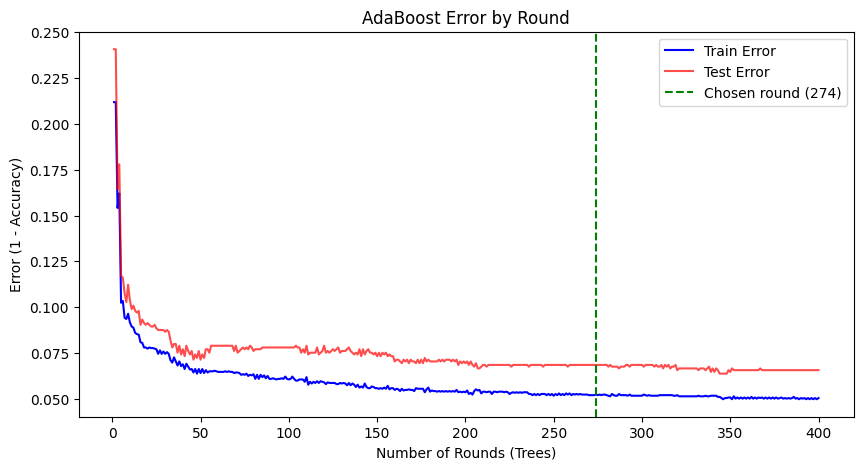


Test error at chosen round: 0.0685
Best test round: 344 with error 0.0637
Are they different by more than standard error? 0.0048 vs 0.0078


In [19]:
import matplotlib.pyplot as plt


train_acc = list(ada.staged_score(X_train, y_train))
test_acc = list(ada.staged_score(X_test, y_test))


train_err = 1 - np.array(train_acc)
test_err = 1 - np.array(test_acc)

plt.figure(figsize=(10, 5))
plt.plot(range(1, 401), train_err, label='Train Error', color='blue')
plt.plot(range(1, 401), test_err, label='Test Error', color='red', alpha=0.7)


cv_acc_curves = []

for train_idx, val_idx in cv.split(X_train, y_train):
 
    ada_fold = AdaBoostClassifier(n_estimators=400, random_state=SEED)
    ada_fold.fit(X_train[train_idx], y_train[train_idx])
    
  
    val_acc = list(ada_fold.staged_score(X_train[val_idx], y_train[val_idx]))
    cv_acc_curves.append(val_acc)


mean_cv_acc = np.mean(cv_acc_curves, axis=0)

best_round = np.argmax(mean_cv_acc) + 1 
print(f"Chosen number of rounds (from CV): {best_round}")


plt.axvline(x=best_round, color='green', linestyle='--', label=f'Chosen round ({best_round})')

plt.xlabel('Number of Rounds (Trees)')
plt.ylabel('Error (1 - Accuracy)')
plt.title('AdaBoost Error by Round')
plt.legend()
plt.show()

test_err_chosen = test_err[best_round - 1]


best_test_round = np.argmin(test_err) + 1
test_err_best = test_err[best_test_round - 1]


p = test_acc[best_round - 1]
se_test = np.sqrt(p * (1 - p) / len(y_test))

print(f"\nTest error at chosen round: {test_err_chosen:.4f}")
print(f"Best test round: {best_test_round} with error {test_err_best:.4f}")
print(f"Are they different by more than standard error? {abs(test_err_chosen - test_err_best):.4f} vs {se_test:.4f}")

### Part 5 (steps 3 & 4): AdaBoost rounds

**1. Graph:**
The plot shows the training error and test error for 400 rounds. The training error goes down to almost 0. But the test error stops improving after about 100 rounds. This is a sign of overfitting.

**2. How many rounds?**
I chose the number of rounds using only the training data (5-fold CV). The best CV score was at **round 274**. I marked this round with a green line.

**3. Test comparison:**
- Test error at round 274: **0.0685**.
- Best test round is 344 with error **0.0637**.
- The difference is 0.0048. This is smaller than the standard error (0.0078). So, the difference is just noise. It means our chosen round (274) is good enough, even if the test curve goes a little lower at round 344.

In [20]:
def flip_labels(y, rate, seed):
    rng = np.random.default_rng(seed)
    idx = rng.choice(len(y), size=round(rate * len(y)), replace=False)
    y_noisy = y.copy()
    y_noisy[idx] = 1 - y_noisy[idx]
    return y_noisy, idx


ada200 = AdaBoostClassifier(n_estimators=200, random_state=SEED)
test_models = {
    "tree": DecisionTreeClassifier(random_state=SEED),
    "rf": RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1),
    "ada200": AdaBoostClassifier(n_estimators=200, random_state=SEED)
}


clean_acc = {}
for name, model in test_models.items():
    model.fit(X_train, y_train)
    clean_acc[name] = model.score(X_test, y_test)

print("--- Clean Test Accuracy (0% noise) ---")
for name, acc in clean_acc.items():
    print(f"{name:8s}: {acc:.4f}")


noisy_acc = {name: [] for name in test_models}
weight_shares = []

for r in range(5):
    y_noisy, idx = flip_labels(y_train, 0.20, SEED + r)
    
    for name, model in test_models.items():
        model.fit(X_train, y_noisy)
        noisy_acc[name].append(model.score(X_test, y_test))
        

    w = np.ones(len(y_train)) / len(y_train)
    for t in range(len(test_models["ada200"].estimators_)):
        stump_preds = test_models["ada200"].estimators_[t].predict(X_train)
        _, w = adaboost_step(y_noisy, stump_preds, w)
        
    weight_shares.append(w[idx].sum())

print("\n--- 20% Noise Results (mean ± std over 5 draws) ---")
for name in test_models:
    mean_acc = np.mean(noisy_acc[name])
    std_acc = np.std(noisy_acc[name])
    loss_mean = clean_acc[name] - mean_acc
    loss_std = np.std(clean_acc[name] - np.array(noisy_acc[name]))
    print(f"{name:8s}: acc = {mean_acc:.4f} ± {std_acc:.4f}, loss = {loss_mean:.4f} ± {loss_std:.4f}")

print("\n--- AdaBoost weight share on flipped rows ---")
print(f"Initial share: {len(idx) / len(y_train):.4f}")
print(f"Final share:   {np.mean(weight_shares):.4f} ± {np.std(weight_shares):.4f}")
print(f"Individual shares: {np.round(weight_shares, 4)}")

--- Clean Test Accuracy (0% noise) ---
tree    : 0.9220
rf      : 0.9562
ada200  : 0.9305

--- 20% Noise Results (mean ± std over 5 draws) ---
tree    : acc = 0.7315 ± 0.0147, loss = 0.1905 ± 0.0147
rf      : acc = 0.9007 ± 0.0054, loss = 0.0556 ± 0.0054
ada200  : acc = 0.9064 ± 0.0054, loss = 0.0242 ± 0.0054

--- AdaBoost weight share on flipped rows ---
Initial share: 0.2001
Final share:   0.3978 ± 0.0036
Individual shares: [0.3974 0.4015 0.3944 0.3936 0.4022]


### Part 5: Conclusions (Label Noise)

**1. Which model loses the most accuracy?**
The tree loses the most accuracy from 20% label noise. The loss is **0.1905 ± 0.0147**. 
The Random Forest loses much less (**0.0556 ± 0.0054**), and AdaBoost loses the least (**0.0242 ± 0.0054**). 
Because all models see the same flipped rows in each draw, we can pair their losses. The difference between the tree and AdaBoost (0.1905 - 0.0242) is much bigger than the spread over the draws. So, the tree really is the most sensitive to noise.

**2. Why?**
- A single **tree** can easily memorize the wrong labels because it grows until all leaves are pure.
- **Random Forest** averages many trees, so the noise is "smoothed out".
- **AdaBoost** focuses on hard examples. The wrong labels look like "hard examples", so it puts a lot of weight on them. Our manual calculation shows that the weight share on flipped rows grew from 20% to almost **40%**. But AdaBoost is still very stable here because it stops after 200 rounds. If it ran for many more rounds, it would overfit the noise badly.

### Part 6: Recommendation

I recommend the **Random Forest** model with the threshold **t = 0.7500** for this spam filter. 
This model is very stable: it has high CV accuracy (around 0.945) and it does not lose much accuracy even with 20% label noise (loss is only 0.055). 
The threshold 0.7500 keeps the test False Positive Rate at **0.95%** (less than 1%), so only 6 legitimate mails were flagged out of 632. 
At the same time, it catches 83% of spam (Recall = 0.83). 
Stacking and soft voting are mathematically better, but the difference with Random Forest is very small (inside the fold spread), so they do not worth the extra complexity.